# 03 — Risque de base

**Question.** Le contrat paie-t-il quand le client a des pertes, et seulement dans ce cas-là ?
Le risque de base est l'écart entre le paiement de l'indice et la perte réelle. Deux erreurs :
- **perte sans paiement** (le client est mal couvert) ;
- **paiement sans perte** (l'assureur paie pour rien).

**Données.** Rendements AOP de l'Yonne (douanes, 2009–2025), indice $Z$ (station de Chablis).
Perte : taux de perte ≥ 20 % par rapport à une référence. Deux références :
moyenne **triennale** (14 années, 2012–2025) et moyenne **olympique** (12 années, 2014–2025).

**Structure évaluée** (fixée dans 02_tarification) : $z_1 = -4{,}7$ °C, $z_2 = -6{,}0$ °C.
Le contrat paie dès que $Z \le z_1$.

**Limites connues.** Rendements à la maille du département, pas de la coopérative ;
pertes de causes mêlées (gel, grêle, maladies), qu'un indice gel ne peut pas toutes couvrir.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent
PROC = ROOT / "data" / "processed"

Z = pd.read_csv(PROC / "indice_Z_chablis_1963_2026.csv").set_index("annee")["Z"]
yonne = pd.read_csv(PROC / "douanes_yonne_aop_2009_2025.csv")

LIMITE = 2_000_000
Z1, Z2 = -4.7, -6.0          # structure retenue dans 02_tarification
SEUIL_PERTE = 0.20

def moyenne_olympique(fenetre):
    # Moyenne de 5 valeurs sans la plus haute ni la plus basse
    return (fenetre.sum() - fenetre.max() - fenetre.min()) / (len(fenetre) - 2)

def table_pertes(reference):
    # Taux de perte annuel par rapport à la référence (l'année t est exclue de sa propre référence)
    t = (yonne[["annee", "rendement_aop_hl_ha"]].sort_values("annee")
         .rename(columns={"rendement_aop_hl_ha": "rendement"}).reset_index(drop=True))
    if reference == "triennale":
        t["reference"] = t["rendement"].rolling(3).mean().shift(1)
    else:
        t["reference"] = t["rendement"].rolling(5).apply(moyenne_olympique, raw=True).shift(1)
    t["taux_perte"] = 1 - t["rendement"] / t["reference"]
    t["perte"] = t["taux_perte"] >= SEUIL_PERTE
    t = t.dropna(subset=["reference"]).merge(Z.rename("Z").reset_index(), on="annee")
    t["declenche"] = t["Z"] < Z1
    t["paiement_k€"] = LIMITE * np.clip((Z1 - t["Z"]) / (Z1 - Z2), 0, 1) / 1e3
    return t

bases = {"triennale": table_pertes("triennale"), "olympique": table_pertes("olympique")}
assert len(bases["triennale"]) == 14 and len(bases["olympique"]) == 12

for nom, b in bases.items():
    print(f"Référence {nom} : {len(b)} années ({b['annee'].min()}–{b['annee'].max()}), "
          f"pertes : {b.loc[b['perte'], 'annee'].tolist()}")

Référence triennale : 14 années (2012–2025), pertes : [2013, 2016, 2021, 2024]
Référence olympique : 12 années (2014–2025), pertes : [2016, 2021, 2024]


## Pertes en fonction de l'indice

Chaque point est une année. Zone orange : le contrat paie ($Z < z_1$). Ligne pointillée : seuil de perte de 20 %.
Si l'indice décrivait bien les pertes, les points rouges seraient dans la zone orange et les bleus à droite.

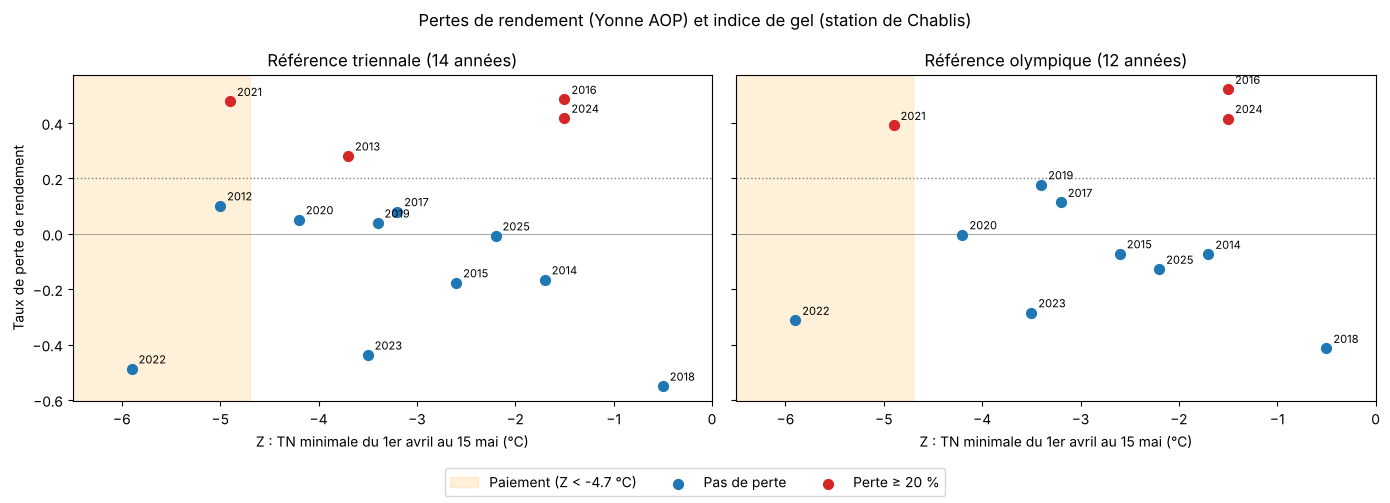

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharey=True)
for ax, (nom, b) in zip(axes, bases.items()):
    ax.axvspan(Z2 - 0.5, Z1, color="orange", alpha=0.15, label=f"Paiement (Z < {Z1} °C)")
    for est_perte, couleur, label in [(False, "tab:blue", "Pas de perte"), (True, "tab:red", "Perte ≥ 20 %")]:
        sel = b[b["perte"] == est_perte]
        ax.scatter(sel["Z"], sel["taux_perte"], color=couleur, label=label, s=50, zorder=3)
    for _, l in b.iterrows():
        ax.annotate(int(l["annee"]), (l["Z"], l["taux_perte"]), textcoords="offset points",
                    xytext=(5, 4), fontsize=8)
    ax.axhline(SEUIL_PERTE, color="grey", linestyle=":", linewidth=1)
    ax.axhline(0, color="grey", linewidth=0.5)
    ax.set_xlim(Z2 - 0.5, 0)
    ax.set_xlabel("Z : TN minimale du 1er avril au 15 mai (°C)")
    ax.set_title(f"Référence {nom} ({len(b)} années)")
axes[0].set_ylabel("Taux de perte de rendement")
poignees, etiquettes = axes[0].get_legend_handles_labels()
fig.legend(poignees, etiquettes, loc="lower center", ncol=3)     # légende sous les graphes : ne cache aucun point
fig.suptitle("Pertes de rendement (Yonne AOP) et indice de gel (station de Chablis)")
plt.tight_layout(rect=[0, 0.07, 1, 1]); plt.show()

## Table de contingence

Lignes : perte ou non. Colonnes : le contrat paie ou non.

In [3]:
for nom, b in bases.items():
    table = pd.crosstab(b["perte"].map({True: "Perte", False: "Pas de perte"}),
                        b["declenche"].map({True: "Paiement", False: "Pas de paiement"}))
    table = table.reindex(index=["Perte", "Pas de perte"], columns=["Paiement", "Pas de paiement"], fill_value=0)
    print(f"--- Référence {nom}")
    print(table.to_string())
    print("Pertes sans paiement :", b.loc[b["perte"] & ~b["declenche"], "annee"].tolist())
    print("Paiements sans perte :", b.loc[~b["perte"] & b["declenche"], "annee"].tolist())
    print()

# Détail année par année (référence triennale), trié par Z
print(bases["triennale"][["annee", "Z", "taux_perte", "perte", "paiement_k€"]]
      .sort_values("Z").round({"taux_perte": 2, "paiement_k€": 0}).to_string(index=False))

--- Référence triennale
declenche     Paiement  Pas de paiement
perte                                  
Perte                1                3
Pas de perte         2                8
Pertes sans paiement : [2013, 2016, 2024]
Paiements sans perte : [2012, 2022]

--- Référence olympique
declenche     Paiement  Pas de paiement
perte                                  
Perte                1                2
Pas de perte         1                8
Pertes sans paiement : [2016, 2024]
Paiements sans perte : [2022]

 annee    Z  taux_perte  perte  paiement_k€
  2022 -5.9       -0.49  False       1846.0
  2012 -5.0        0.10  False        462.0
  2021 -4.9        0.48   True        308.0
  2020 -4.2        0.05  False          0.0
  2013 -3.7        0.28   True          0.0
  2023 -3.5       -0.44  False          0.0
  2019 -3.4        0.04  False          0.0
  2017 -3.2        0.08  False          0.0
  2015 -2.6       -0.18  False          0.0
  2025 -2.2       -0.01  False          0.0
  

## Probabilités d'erreur $q$ et $r$

$$q = P(\text{pas de paiement} \mid \text{perte}), \qquad r = P(\text{pas de perte} \mid \text{paiement})$$

- $q$ : risque pour le **client** (il perd et n'est pas payé) ;
- $r$ : risque pour l'**assureur** (il paie sans perte, ce qui renchérit la prime).

Estimées par des proportions dans la table de contingence. Intervalle de confiance exact de Clopper-Pearson à 95 % : avec $k$ succès sur $n$, les bornes sont des quantiles de lois beta,
$\big[\,B^{-1}(2{,}5\,\% ; k, n-k+1)\,;\ B^{-1}(97{,}5\,\% ; k+1, n-k)\,\big]$.

In [4]:
from scipy.stats import beta

def clopper_pearson(k, n, niveau=0.95):
    a = 1 - niveau
    bas = 0.0 if k == 0 else beta.ppf(a / 2, k, n - k + 1)
    haut = 1.0 if k == n else beta.ppf(1 - a / 2, k + 1, n - k)
    return bas, haut

lignes = {}
for nom, b in bases.items():
    n_perte, k_q = int(b["perte"].sum()), int((b["perte"] & ~b["declenche"]).sum())
    n_paie, k_r = int(b["declenche"].sum()), int((~b["perte"] & b["declenche"]).sum())
    (q_bas, q_haut), (r_bas, r_haut) = clopper_pearson(k_q, n_perte), clopper_pearson(k_r, n_paie)
    lignes[nom] = {"q": f"{k_q}/{n_perte} = {k_q/n_perte:.0%}  [{q_bas:.0%} ; {q_haut:.0%}]",
                   "r": f"{k_r}/{n_paie} = {k_r/n_paie:.0%}  [{r_bas:.0%} ; {r_haut:.0%}]"}

print("Estimation  [IC 95 % de Clopper-Pearson]\n")
print(pd.DataFrame(lignes).T.to_string())

Estimation  [IC 95 % de Clopper-Pearson]

                                q                      r
triennale  3/4 = 75%  [19% ; 99%]  2/3 = 67%  [9% ; 99%]
olympique   2/3 = 67%  [9% ; 99%]  1/2 = 50%  [1% ; 99%]


## Conclusion

- **Contingence** (référence triennale) : 1 perte sur 4 donne lieu à paiement (2021) ;
  3 pertes sans paiement (2013, 2016, 2024) ; 2 paiements sans perte (2012, 2022).
  Référence olympique : 2012 et 2013 sortent de l'échantillon ; 1 perte payée sur 3, 1 paiement sans perte (2022).
- **Probabilités d'erreur** (triennale) : $q = 3/4$, IC 95 % [19 % ; 99 %] ; $r = 2/3$, IC 95 % [9 % ; 99 %].
  Les estimations sont mauvaises, mais reposent sur 4 pertes et 3 paiements : les intervalles couvrent presque tout
  l'intervalle [0 ; 1]. Les données ne permettent ni de conclure que l'indice est mauvais, ni qu'il est bon.

**Autre station ou mesure plus près du sol ?** Examiné dans `04_annexe_stations.ipynb` : aucune station voisine (jusqu'à 45 km),
ni TN50 ou TNSOL là où ils existent, ne classe 2016 et 2024 parmi les années froides. Le risque de base ne vient donc pas
d'un capteur mal placé, mais de pertes de causes mêlées.

**Ce qu'il faudrait pour mesurer le risque de base** : rendements ou sinistres à la maille de la coopérative,
série plus longue, cause des pertes (déclarations gel distinctes de la grêle et des maladies).